# **Section 11: Presence/absence CNVs and the replication-rate confounder**

Notebook 10 runs the models on the **continuous** log2 depth ratios. This notebook keeps that
analysis untouched and repeats it on a **presence/absence** version of the same matrix, because
the continuous depths carry a confounder that has nothing to do with resistance.

**The problem.** Depth at `dnaA`, the gene at the origin of replication, is the single best
discriminator of SXT resistance in the whole matrix (rank-biserial effect +0.83, adjusted
p = 3e-23). The replication gradient itself, measured as the peak-to-trough ratio (PTR) of
smoothed depth along the genome, is almost twice as steep in resistant isolates (median 0.46
against 0.24, p = 4e-19). A steep gradient means the cells were replicating actively when the
DNA was extracted, so this is growth state, not genotype. On ST-grouped cross-validation:

| predictor | accuracy | AUC |
|---|---|---|
| `dnaA` depth alone, a single number | 0.740 | 0.910 |
| PTR alone, a single number | 0.816 | 0.846 |
| seven per-sample summary statistics | 0.886 | 0.922 |
| the full 11718-region continuous matrix | 0.877 | 0.904 |

A single ori-proximal gene matches the entire model, so the continuous result cannot be
reported as a copy-number finding without qualification.

**Two possible fixes were tested, and only one works.** Excluding ori-proximal regions does
not help: dropping a window of +/-2000 genes around `dnaA`, a third of the genome, leaves the
AUC at 0.914 and the growth signal still readable in what remains (rho between mean depth and
PTR = +0.48). A replication gradient is genome-wide, so removing the peak does not remove the
gradient. Turning the matrix into presence/absence calls does work, and that is what this
notebook does.

**Contents**
1. Load the data and binarise it
2. Choice of threshold
3. Outer folds by sequence type
4. Feature selection inside each fold
5. Nested cross-validation
6. Checking that the confounder is gone
7. The regions selected in every fold
8. Figures

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import false_discovery_control, mannwhitneyu, spearmanr
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
sns.set_palette('pastel')

## **1. Load the data and binarise it**

In [2]:
# The same split and the same matrix that notebook 10 uses
cnv_train = pd.read_csv("Data/cnv_train.csv", index_col=0)
cnv_test = pd.read_csv("Data/cnv_test.csv", index_col=0)
profiles_train = pd.read_csv("Data/SXT_train.csv", index_col=0)
profiles_test = pd.read_csv("Data/SXT_test.csv", index_col=0)

cnv_all = pd.concat([cnv_train, cnv_test], axis=0)
profiles = pd.concat([profiles_train, profiles_test], axis=0).loc[cnv_all.index]

metadata = pd.read_csv("../genome_metadata_cleaned.csv", index_col=0, dtype={'ST': str})
metadata = metadata.loc[cnv_all.index, :]
metadata['ST'] = metadata['ST'].fillna('unknown')

y = profiles.iloc[:, 0].values
print(f'{cnv_all.shape[0]} samples, {cnv_all.shape[1]} regions')
print(f'{int((y==1).sum())} resistant, {int((y==0).sum())} susceptible')

227 samples, 23310 regions
123 resistant, 104 susceptible


Each gene appears in the matrix more than once, as a `__gene` entry and one or more
`__CDS` or `__promoter` entries holding exactly the same depths. Those copies are not
independent tests, so the duplicates are dropped before anything is corrected for multiple
testing.

In [3]:
duplicated = cnv_all.T.duplicated().values
cnv_all = cnv_all.loc[:, ~duplicated]
print(f'{duplicated.sum()} duplicate region columns dropped, {cnv_all.shape[1]} regions left')

11592 duplicate region columns dropped, 11718 regions left


A region is called **absent** when its log2 depth ratio falls below the threshold. The
value is a ratio, so 0 means the same depth as the reference and -1 means half of it.

In [4]:
ABSENT_THRESHOLD = -1.0

B = (cnv_all < ABSENT_THRESHOLD).astype(int)
print(f'{100*B.values.mean():.2f}% of all cells are called absent')
print(f'absent calls per sample: median {int(B.sum(axis=1).median())}, '
      f'range {int(B.sum(axis=1).min())}-{int(B.sum(axis=1).max())}')
print(f'{int((B.sum(axis=0) > 0).sum())} regions are absent in at least one sample')

3.47% of all cells are called absent
absent calls per sample: median 344, range 188-5756


9092 regions are absent in at least one sample


## **2. Choice of threshold**

The threshold matters, and not in the way one would expect. The table below counts, for each
candidate threshold, how many regions are significantly associated with resistance on the
whole data set. Only the mild threshold yields any; requiring complete absence yields none.
The discriminating signal is therefore **partial depletion**, around a quarter to a half of
the reference depth, and not the complete loss of an accessory region.

In [5]:
rows = []
for name, M in [('absent if log2 < -1', (cnv_all < -1).astype(int)),
                ('absent if log2 < -2', (cnv_all < -2).astype(int)),
                ('absent if log2 < -5', (cnv_all < -5).astype(int)),
                ('gain if log2 > +1', (cnv_all > 1).astype(int)),
                ('deviant if |log2| > 1', (cnv_all.abs() > 1).astype(int))]:
    keep = M.loc[:, M.std(axis=0) > 0]
    scores, p = chi2(keep.values, y)
    p_adj = false_discovery_control(np.nan_to_num(p, nan=1.0), method='bh')
    rows.append({'encoding': name, 'cells set': f'{100*M.values.mean():.2f}%',
                 'regions varying': keep.shape[1], 'significant': int((p_adj < 0.05).sum())})
print(pd.DataFrame(rows).to_string(index=False))

             encoding cells set  regions varying  significant
  absent if log2 < -1     3.47%             9052           18
  absent if log2 < -2     2.71%             8456            0
  absent if log2 < -5     2.53%             8267            1
    gain if log2 > +1     0.65%             8737            0
deviant if |log2| > 1     4.11%            11666           16


## **3. Outer folds by sequence type**

The folds are built exactly as in notebook 10: each sequence type goes whole into one fold, so
every fold tests on lineages that were not trained on. Samples with no known ST are grouped
together as `unknown`.

In [6]:
n_splits = 10
ST_df = metadata['ST'].value_counts().rename_axis('ST').reset_index(name='count')

split_counts = [0] * n_splits
split_assignment = []
for _, sample in ST_df.iterrows():
    split = split_counts.index(min(split_counts))
    split_assignment.append(split)
    split_counts[split] += sample['count']
ST_df['split'] = split_assignment

metadata['split'] = metadata['ST'].map(ST_df.set_index('ST')['split'])
print(f'samples per fold: {split_counts}')
print(pd.crosstab(metadata['split'], y, rownames=['fold'], colnames=['SXT']))

samples per fold: [23, 23, 23, 23, 23, 23, 23, 22, 22, 22]
SXT    0   1
fold        
0     12  11
1      8  15
2     13  10
3     11  12
4      9  14
5     11  12
6     10  13
7      9  13
8     16   6
9      5  17


## **4. Feature selection inside each fold**

The selector keeps the regions significantly associated with resistance by a chi2 test on the
absence calls, with Benjamini-Hochberg correction, and falls back to the best 200 by chi2
score if fewer than five are significant. It is fitted on the training part of each outer fold
only, so no fold helps choose its own features.

No variance filter is applied: the chi2 test together with the correction already discards
regions that are absent in only a handful of samples.

In [7]:
class BinaryFoldSelector(BaseEstimator, TransformerMixin):
    """Pick the absence calls associated with resistance, refitted on one fold's training part."""

    def __init__(self, alpha=0.05, min_features=5, fallback_k=200):
        self.alpha = alpha
        self.min_features = min_features
        self.fallback_k = fallback_k

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y).ravel()
        varying = np.flatnonzero(X.std(axis=0) > 0)
        scores, p = chi2(X[:, varying], y)
        p_adj = false_discovery_control(np.nan_to_num(p, nan=1.0), method='bh')
        self.n_significant_ = int((p_adj < self.alpha).sum())
        if self.n_significant_ >= self.min_features:
            chosen = np.flatnonzero(p_adj < self.alpha)
        else:
            chosen = np.argsort(-np.nan_to_num(scores, nan=-np.inf))[:self.fallback_k]
        self.support_ = varying[np.sort(chosen)]
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.support_]

## **5. Nested cross-validation**

In [8]:
def nested_cross_validation(model_name, pipeline, param_grid, X, y, cv_inner=5):
    """Nested CV with the absence calls selected inside each outer fold."""
    outer_folds = sorted(metadata['split'].unique())
    accuracies, aucs, best_params, n_features, n_significant = [], [], [], [], []
    fold_predictions = []
    common_grid = np.linspace(0, 1, 100)
    fold_tprs = []

    for fold in outer_folds:
        train_idx = (metadata['split'] != fold).values
        test_idx = (metadata['split'] == fold).values
        X_train, y_train = X[train_idx], y[train_idx]
        X_test, y_test = X[test_idx], y[test_idx]

        selector = BinaryFoldSelector().fit(X_train, y_train)
        X_train, X_test = selector.transform(X_train), selector.transform(X_test)
        n_features.append(X_train.shape[1])
        n_significant.append(selector.n_significant_)

        grid_search = GridSearchCV(pipeline, param_grid,
                                   cv=StratifiedKFold(n_splits=cv_inner, shuffle=True, random_state=2),
                                   scoring='accuracy', n_jobs=-1)
        grid_search.fit(X_train, y_train)
        y_pred = grid_search.predict(X_test)
        y_proba = grid_search.predict_proba(X_test)[:, 1]

        accuracies.append(accuracy_score(y_test, y_pred))
        best_params.append(grid_search.best_params_)
        fold_predictions.append(pd.DataFrame({
            'sample_id': cnv_all.index[test_idx], 'fold': fold,
            'y_true': y_test, 'y_pred': y_pred, 'y_proba': y_proba}))

        if len(np.unique(y_test)) == 2:
            auc = roc_auc_score(y_test, y_proba)
            fpr, tpr, _ = roc_curve(y_test, y_proba)
            interp_tpr = np.interp(common_grid, fpr, tpr)
            interp_tpr[0] = 0.0
            fold_tprs.append(interp_tpr)
        else:
            auc = np.nan
        aucs.append(auc)
        print(f'{model_name}, Fold {fold}: {X_train.shape[1]} features '
              f'({selector.n_significant_} significant), Accuracy={accuracies[-1]:.4f}, AUC={auc:.4f}')

    n_folds = len(outer_folds)
    n_auc_folds = int(np.sum(~np.isnan(aucs)))
    mean_tpr = np.mean(fold_tprs, axis=0)
    mean_tpr[-1] = 1.0
    return {
        'model_name': model_name,
        'accuracies': np.array(accuracies), 'aucs': np.array(aucs),
        'accuracy_mean': np.mean(accuracies), 'accuracy_std': np.std(accuracies),
        'accuracy_ci': 1.96 * np.std(accuracies) / np.sqrt(n_folds),
        'auc_mean': np.nanmean(aucs), 'auc_std': np.nanstd(aucs),
        'auc_ci': 1.96 * np.nanstd(aucs) / np.sqrt(n_auc_folds),
        'best_params_list': best_params,
        'n_features_per_fold': n_features, 'n_significant_per_fold': n_significant,
        'mean_fpr': common_grid, 'mean_tpr': mean_tpr, 'std_tpr': np.std(fold_tprs, axis=0),
        'predictions': pd.concat(fold_predictions, ignore_index=True),
    }

In [9]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5,
                                  max_iter=1000, random_state=4)),
])
lr_param_grid = {'logreg__C': np.logspace(-2, 2, 5), 'logreg__l1_ratio': [0.0, 0.25, 0.5, 0.75, 1.0]}

xgb_model = xgb.XGBClassifier(n_estimators=100, random_state=1, eval_metric='logloss')
xgb_param_grid = {'max_depth': [3, 5, 7], 'learning_rate': [0.05, 0.1],
                  'reg_alpha': [0.0, 0.1], 'reg_lambda': [0.1, 1.0]}

knn_pipeline = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
knn_param_grid = {'knn__n_neighbors': [5, 10, 15, 20, 30, 35, 40]}

X = B.values

In [10]:
results_lr = nested_cross_validation('Logistic Regression', lr_pipeline, lr_param_grid, X, y)
print()
results_xgb = nested_cross_validation('XGB', xgb_model, xgb_param_grid, X, y)
print()
results_knn = nested_cross_validation('KNN', knn_pipeline, knn_param_grid, X, y)

Logistic Regression, Fold 0: 14 features (14 significant), Accuracy=0.9565, AUC=0.9962


Logistic Regression, Fold 1: 18 features (18 significant), Accuracy=0.8696, AUC=0.8083


Logistic Regression, Fold 2: 13 features (13 significant), Accuracy=0.9130, AUC=0.9615


Logistic Regression, Fold 3: 17 features (17 significant), Accuracy=0.9565, AUC=0.9470


Logistic Regression, Fold 4: 15 features (15 significant), Accuracy=0.8696, AUC=0.9762


Logistic Regression, Fold 5: 19 features (19 significant), Accuracy=0.6087, AUC=0.6818


... (15 outputs left out)

KNN, Fold 3: 17 features (17 significant), Accuracy=0.9565, AUC=0.9811
KNN, Fold 4: 15 features (15 significant), Accuracy=0.8696, AUC=0.9683


KNN, Fold 5: 19 features (19 significant), Accuracy=0.6087, AUC=0.5758
KNN, Fold 6: 17 features (17 significant), Accuracy=0.7391, AUC=0.9077


KNN, Fold 7: 15 features (15 significant), Accuracy=1.0000, AUC=1.0000
KNN, Fold 8: 14 features (14 significant), Accuracy=0.9091, AUC=0.9792


KNN, Fold 9: 14 features (14 significant), Accuracy=0.7727, AUC=1.0000


In [11]:
all_results = [results_lr, results_xgb, results_knn]

summary = pd.DataFrame([{
    'Model': r['model_name'],
    'Accuracy': f"{r['accuracy_mean']:.4f} ± {r['accuracy_std']:.4f}",
    'Accuracy (95% CI)': f"[{r['accuracy_mean']-r['accuracy_ci']:.4f}, {r['accuracy_mean']+r['accuracy_ci']:.4f}]",
    'AUC': f"{r['auc_mean']:.4f} ± {r['auc_std']:.4f}",
    'AUC (95% CI)': f"[{r['auc_mean']-r['auc_ci']:.4f}, {r['auc_mean']+r['auc_ci']:.4f}]",
    'features/fold': int(np.mean(r['n_features_per_fold'])),
} for r in all_results])

print('Nested cross-validation on the presence/absence matrix:')
print(summary.to_string(index=False))
summary.to_csv('Results/nested_cv_results_binary.csv', index=False)

for r in all_results:
    r['predictions'].to_csv(
        f"Results/{r['model_name'].lower().replace(' ', '_')}_predictions_SXT_binary.csv", index=False)
print('\nsaved Results/nested_cv_results_binary.csv and the out-of-fold predictions')

Nested cross-validation on the presence/absence matrix:
              Model        Accuracy Accuracy (95% CI)             AUC     AUC (95% CI)  features/fold
Logistic Regression 0.8818 ± 0.1047  [0.8169, 0.9467] 0.9237 ± 0.0974 [0.8633, 0.9841]             15
                XGB 0.8468 ± 0.1166  [0.7746, 0.9191] 0.9291 ± 0.1145 [0.8582, 1.0001]             15
                KNN 0.8595 ± 0.1136  [0.7891, 0.9299] 0.9318 ± 0.1221 [0.8561, 1.0075]             15

saved Results/nested_cv_results_binary.csv and the out-of-fold predictions


The numbers to compare against are the continuous ones from notebook 10, and the
confounder-only baselines quoted in the introduction. The binarised matrix should hold its
accuracy while using far fewer features; the next section checks that it no longer carries the
growth signal.

## **6. Checking that the confounder is gone**

The replication gradient is measured per sample as the peak-to-trough ratio of depth smoothed
along the genome. Locus tag numbers run along the chromosomes, so sorting regions by tag number
gives an approximate genomic order; this is a diagnostic, not a precise coordinate system, and
it concatenates the two replicons.

In [12]:
tag_column = {}
for col in cnv_all.columns:
    m = re.search(r'IBNLCO_(\d+)', col)
    if m:
        tag_column.setdefault(int(m.group(1)), col)
ordered = [tag_column[t] for t in sorted(tag_column)]

smoothed = cnv_all[ordered].T.rolling(150, center=True, min_periods=75).median().T
ptr = smoothed.max(axis=1) - smoothed.min(axis=1)
dnaA = cnv_all.filter(like='dnaA').mean(axis=1)

print('the confounder itself, resistant vs susceptible:')
for name, v in [('peak-to-trough ratio', ptr), ('dnaA depth', dnaA)]:
    a, b = v[y == 1], v[y == 0]
    effect = 2 * mannwhitneyu(a, b)[0] / (len(a) * len(b)) - 1
    print(f'  {name:22s} R={a.median():+.3f} S={b.median():+.3f} '
          f'effect={effect:+.2f} p={mannwhitneyu(a, b)[1]:.2e}')

print('\nhow strongly each matrix carries it:')
rows = [('continuous depth, per-sample mean', spearmanr(cnv_all.mean(axis=1), ptr)[0]),
        ('absence calls, per-sample count', spearmanr(B.sum(axis=1), ptr)[0])]
for name, rho in rows:
    print(f'  rho with PTR, {name:38s} {rho:+.2f}')
print(f'  rho between the absence count and mean depth      '
      f'{spearmanr(B.sum(axis=1), cnv_all.mean(axis=1))[0]:+.2f}')

the confounder itself, resistant vs susceptible:
  peak-to-trough ratio   R=+0.457 S=+0.242 effect=+0.69 p=4.34e-19
  dnaA depth             R=+0.130 S=-0.016 effect=+0.87 p=2.25e-29

how strongly each matrix carries it:
  rho with PTR, continuous depth, per-sample mean      +0.29
  rho with PTR, absence calls, per-sample count        +0.14
  rho between the absence count and mean depth      -0.67


A correlation near zero for the absence calls, against a clearly positive one for the
continuous depths, is the point of this notebook: the presence/absence encoding keeps the
region-specific differences and drops the growth state.

## **7. The regions selected in every fold**

Regions picked in all ten folds are the stable part of the signal. The table reports how often
each is absent in resistant and in susceptible strains, and in how many of the larger sequence
types it is mostly absent, which separates genuine markers from single-lineage ones.

These regions are collected across all folds for reporting, so the accuracy and AUC above
remain the honest performance estimate; they are not an estimate for this panel on its own.

In [13]:
from collections import Counter

picked = Counter()
for fold in sorted(metadata['split'].unique()):
    train_idx = (metadata['split'] != fold).values
    selector = BinaryFoldSelector().fit(B.values[train_idx], y[train_idx])
    for col in B.columns[selector.support_]:
        picked[col] += 1

big_st = metadata['ST'].value_counts()
big_st = big_st[big_st >= 5].index
panel = []
for col, n in picked.most_common():
    per_st = B.loc[metadata['ST'].isin(big_st)].groupby(metadata['ST'])[col].mean()
    panel.append({'region': col.replace('cnv_depth__', ''), 'folds': n,
                  'absent_pct_resistant': 100 * B.loc[y == 1, col].mean(),
                  'absent_pct_susceptible': 100 * B.loc[y == 0, col].mean(),
                  'absent_n_samples': int(B[col].sum()),
                  'major_STs_mostly_absent': int((per_st > 0.5).sum()), 'major_STs': len(per_st)})
panel = pd.DataFrame(panel)
panel.to_csv('Results/biomarkers_binary_panel.csv', index=False)

print(f'{len(panel)} regions selected in at least one fold, '
      f'{int((panel.folds == 10).sum())} in all ten')
print(panel[panel.folds == 10].round(1).to_string(index=False))
print('\nsaved Results/biomarkers_binary_panel.csv')

24 regions selected in at least one fold, 11 in all ten
                                      region  folds  absent_pct_resistant  absent_pct_susceptible  absent_n_samples  major_STs_mostly_absent  major_STs
          IBNLCO_00177__mrdA__gene__promoter     10                   3.3                    29.8                35                        3         15
  IBNLCO_00394__IBNLCO_00394__gene__promoter     10                   4.9                    54.8                63                        5         15
  IBNLCO_01121__IBNLCO_01121__gene__promoter     10                   3.3                    25.0                30                        0         15
            IBNLCO_01688__IBNLCO_01688__gene     10                  59.3                    15.4                89                        4         15
IBNLCO_01735__Low-specificity__CDS__promoter     10                  30.9                    75.0               116                        9         15
  IBNLCO_03292__IBNLCO_03292__ge

## **8. Figures**

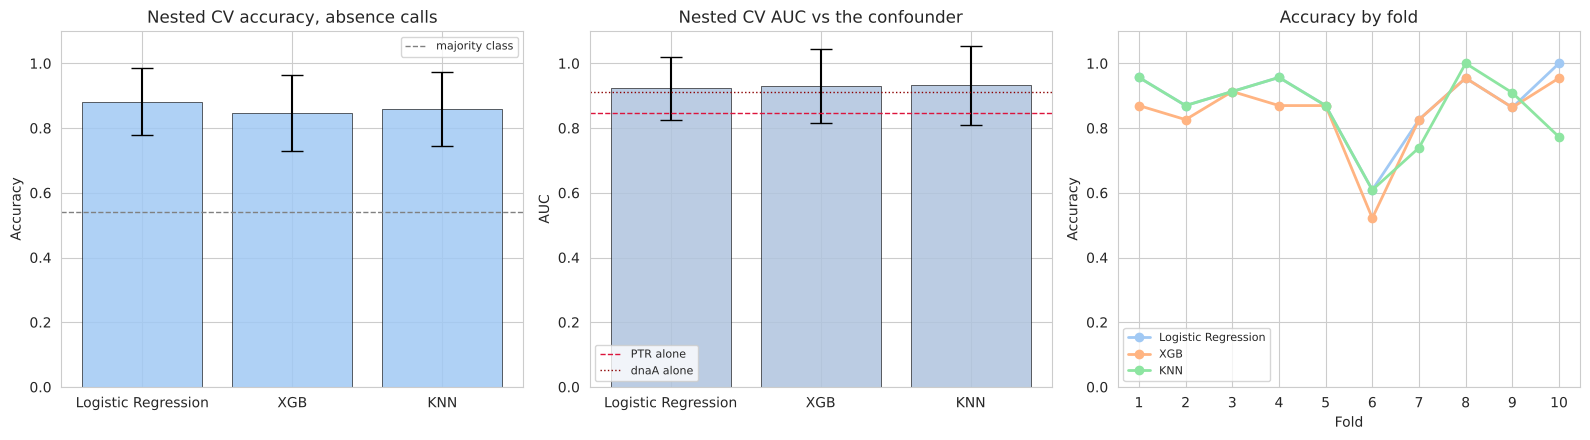

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
models = [r['model_name'] for r in all_results]

axes[0].bar(models, [r['accuracy_mean'] for r in all_results],
            yerr=[r['accuracy_std'] for r in all_results], capsize=8,
            alpha=0.85, edgecolor='black', linewidth=0.5)
axes[0].axhline(max(np.mean(y), 1 - np.mean(y)), ls='--', c='grey', lw=1, label='majority class')
axes[0].set_ylabel('Accuracy'); axes[0].set_ylim(0, 1.1)
axes[0].set_title('Nested CV accuracy, absence calls'); axes[0].legend(fontsize=8)

axes[1].bar(models, [r['auc_mean'] for r in all_results],
            yerr=[r['auc_std'] for r in all_results], capsize=8,
            alpha=0.85, edgecolor='black', linewidth=0.5, color='lightsteelblue')
axes[1].axhline(0.846, ls='--', c='crimson', lw=1, label='PTR alone')
axes[1].axhline(0.910, ls=':', c='darkred', lw=1, label='dnaA alone')
axes[1].set_ylabel('AUC'); axes[1].set_ylim(0, 1.1)
axes[1].set_title('Nested CV AUC vs the confounder'); axes[1].legend(fontsize=8)

folds = np.arange(1, len(results_lr['accuracies']) + 1)
for r in all_results:
    axes[2].plot(folds, r['accuracies'], 'o-', lw=2, ms=6, label=r['model_name'])
axes[2].set_xlabel('Fold'); axes[2].set_ylabel('Accuracy'); axes[2].set_ylim(0, 1.1)
axes[2].set_xticks(folds); axes[2].set_title('Accuracy by fold'); axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('Figures/11_binary_nested_cv.png', dpi=200, bbox_inches='tight')
plt.show()

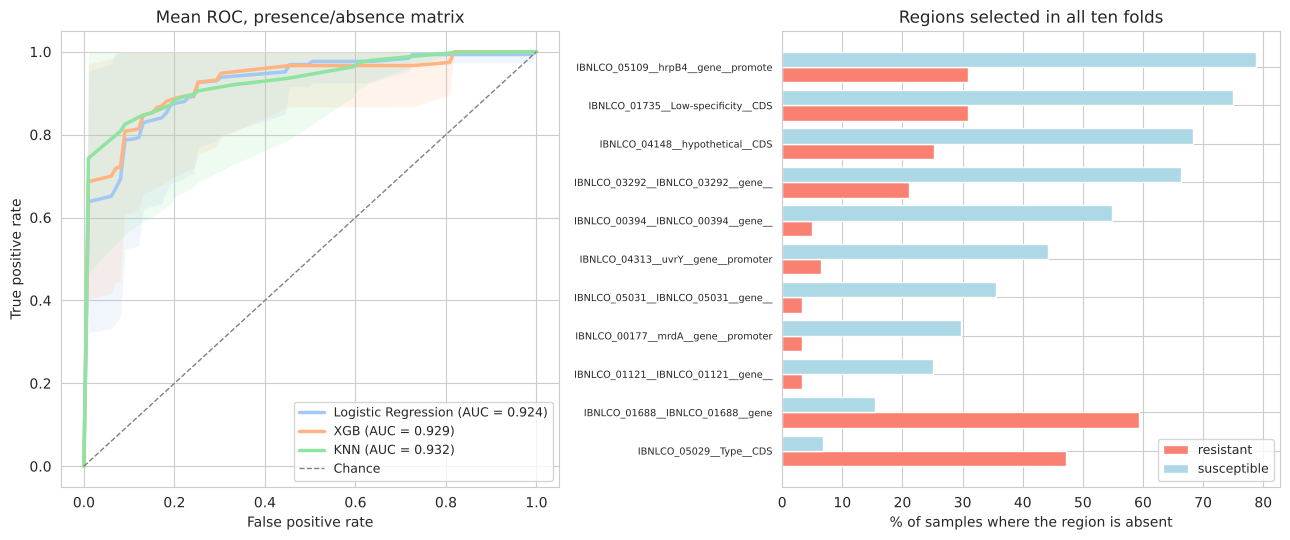

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for r in all_results:
    axes[0].plot(r['mean_fpr'], r['mean_tpr'], lw=2.5,
                 label=f"{r['model_name']} (AUC = {r['auc_mean']:.3f})")
    axes[0].fill_between(r['mean_fpr'], np.maximum(r['mean_tpr'] - r['std_tpr'], 0),
                         np.minimum(r['mean_tpr'] + r['std_tpr'], 1), alpha=0.15)
axes[0].plot([0, 1], [0, 1], ls='--', c='grey', lw=1, label='Chance')
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate')
axes[0].set_title('Mean ROC, presence/absence matrix'); axes[0].legend(fontsize=9, loc='lower right')

stable = panel[panel.folds == 10].sort_values('absent_pct_susceptible')
pos = np.arange(len(stable))
axes[1].barh(pos - 0.2, stable.absent_pct_resistant, height=0.4, label='resistant', color='salmon')
axes[1].barh(pos + 0.2, stable.absent_pct_susceptible, height=0.4, label='susceptible', color='lightblue')
axes[1].set_yticks(pos)
axes[1].set_yticklabels([r[:34] for r in stable.region], fontsize=7)
axes[1].set_xlabel('% of samples where the region is absent')
axes[1].set_title('Regions selected in all ten folds'); axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('Figures/11_binary_panel.png', dpi=200, bbox_inches='tight')
plt.show()

## **9. Conclusions**

In [16]:
print('Ranking by accuracy:')
for i, r in enumerate(sorted(all_results, key=lambda r: -r['accuracy_mean']), 1):
    print(f"  {i}. {r['model_name']}: {r['accuracy_mean']:.3f} ± {r['accuracy_std']:.3f}, "
          f"AUC {r['auc_mean']:.3f}, {int(np.mean(r['n_features_per_fold']))} features/fold")
print()
print('For comparison, on the same folds:')
print('  continuous depth, 11718 regions   accuracy 0.877  AUC 0.904  ~698 features/fold')
print('  seven summary statistics only     accuracy 0.886  AUC 0.922')
print('  dnaA depth alone                  accuracy 0.740  AUC 0.910')

Ranking by accuracy:
  1. Logistic Regression: 0.882 ± 0.105, AUC 0.924, 15 features/fold
  2. KNN: 0.859 ± 0.114, AUC 0.932, 15 features/fold
  3. XGB: 0.847 ± 0.117, AUC 0.929, 15 features/fold

For comparison, on the same folds:
  continuous depth, 11718 regions   accuracy 0.877  AUC 0.904  ~698 features/fold
  seven summary statistics only     accuracy 0.886  AUC 0.922
  dnaA depth alone                  accuracy 0.740  AUC 0.910
